In [1]:
#pip install tensorflow

In [2]:
#pip install opencv-python

In [3]:
import tensorflow as tf
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

import cv2 # OpenCV
from sklearn.preprocessing import LabelEncoder 
from tensorflow.keras.utils import to_categorical 
from sklearn.utils import shuffle

In [4]:
data_path = r"C:\IEEE S2\comp.2\archive (8)\COVID-19_Radiography_Dataset\COVID-19_Radiography_Dataset"

In [5]:
os.listdir(data_path)

['COVID', 'Lung_Opacity', 'Normal', 'Viral Pneumonia']

In [6]:
def load_data(path):
  images = [] 
  labels = []
  for folder in os.listdir(path): 
    for file in os.listdir(os.path.join(path, folder)): 
      image_path = os.path.join(path, folder, file)
      image = cv2.imread(image_path)
      #image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
      image = cv2.resize(image, (128, 128))
      #image = image.reshape(128, 128, 1)
      image = image / 255.0  #rescaling
      images.append(image)
      labels.append(folder)

    # Shuffle the data
  images, labels = shuffle(images, labels, random_state=42)
  return np.array(images), np.array(labels) # arrays

In [7]:
# Load data
X, y = load_data(data_path)

In [8]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [9]:
y_encoded

array([3, 2, 0, ..., 1, 0, 2], dtype=int64)

In [10]:
from collections import Counter

# Check class distribution BEFORE fixing imbalance
label_counts = Counter(y)
print("Class distribution before balancing:", label_counts)

Class distribution before balancing: Counter({'Normal': 10192, 'Lung_Opacity': 6012, 'COVID': 3616, 'Viral Pneumonia': 1345})


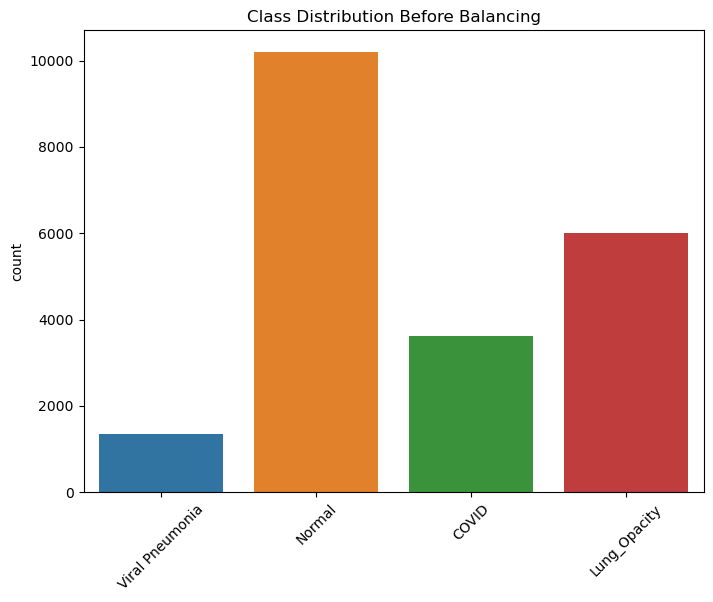

In [11]:
# Visualize class distribution
plt.figure(figsize=(8,6))
sns.countplot(x=y)
plt.title("Class Distribution Before Balancing")
plt.xticks(rotation=45)
plt.show()

In [12]:
# Split data (only split here — we will balance only train)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

In [13]:
# Confirm train distribution
print("Training Class Distribution before balancing:", Counter(y_train))

Training Class Distribution before balancing: Counter({2: 8154, 1: 4809, 0: 2893, 3: 1076})


In [14]:
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter

def random_undersample_class2(X_train, y_train):
    # Flatten X to 2D temporarily because RandomUnderSampler expects 2D (n_samples, n_features)
    X_shape = X_train.shape
    X_flat = X_train.reshape((X_shape[0], -1))

    # Initialize RandomUnderSampler
    rus = RandomUnderSampler(sampling_strategy={2: 5000}, random_state=42)

    # Fit and resample (only class 2 will be reduced to 5000)
    X_resampled, y_resampled = rus.fit_resample(X_flat, y_train)

    # Reshape X back to original shape
    X_train = X_resampled.reshape((-1, X_shape[1], X_shape[2], X_shape[3]))
    y_train = y_resampled

    # Return the undersampled data
    return X_train, y_train

In [15]:
# Call the function to perform random undersampling
X_train, y_train = random_undersample_class2(X_train, y_train)

# Check the class distribution in the undersampled dataset
print("Final Training Class Distribution after Undersampling Class 2:", Counter(y_train))

Final Training Class Distribution after Undersampling Class 2: Counter({2: 5000, 1: 4809, 0: 2893, 3: 1076})


In [16]:
# Create dictionary to hold new balanced data
target_samples_per_class = 5000
X_train_balanced = []
y_train_balanced = []

In [17]:
# Initialize ImageDataGenerator for augmentation
train_gen = ImageDataGenerator(
    shear_range=0.2,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    fill_mode='nearest'
)

In [18]:
# Loop through each class
unique_classes = np.unique(y_train)

for class_label in unique_classes:
    idxs = np.where(y_train == class_label)[0]
    X_class = X_train[idxs]
    y_class = y_train[idxs]
    
    print(f"\nClass {class_label}: {len(X_class)} original samples")
    
    # Add original samples
    X_train_balanced.append(X_class)
    y_train_balanced.append(y_class)
    
    # If samples are less than target, augment
    if len(X_class) < target_samples_per_class:
        # Create a generator for this class
        class_generator = train_gen.flow(X_class, y_class, batch_size=32)
        
        augmented_images = []
        augmented_labels = []
        
        needed = target_samples_per_class - len(X_class)
        batches_needed = int(np.ceil(needed / 32))
        
        for _ in range(batches_needed):
            x_batch, y_batch = next(class_generator)
            augmented_images.append(x_batch)
            augmented_labels.append(y_batch)
        
        augmented_images = np.concatenate(augmented_images, axis=0)[:needed]
        augmented_labels = np.concatenate(augmented_labels, axis=0)[:needed]
        
        X_train_balanced.append(augmented_images)
        y_train_balanced.append(augmented_labels)


Class 0: 2893 original samples

Class 1: 4809 original samples

Class 2: 5000 original samples

Class 3: 1076 original samples


In [19]:
# Concatenate all classes
X_train_balanced = np.concatenate(X_train_balanced, axis=0)
y_train_balanced = np.concatenate(y_train_balanced, axis=0)

In [20]:
# Shuffle the balanced dataset
X_train_balanced, y_train_balanced = shuffle(X_train_balanced, y_train_balanced, random_state=42)

In [21]:
print("\nFinal Training Set Shape:", X_train_balanced.shape, y_train_balanced.shape)


Final Training Set Shape: (19976, 128, 128, 3) (19976,)


In [22]:
# Check final distribution
final_counts = Counter(y_train_balanced)
print("\nFinal Training Class Distribution:", final_counts)


Final Training Class Distribution: Counter({1: 5000, 2: 5000, 0: 5000, 3: 4976})


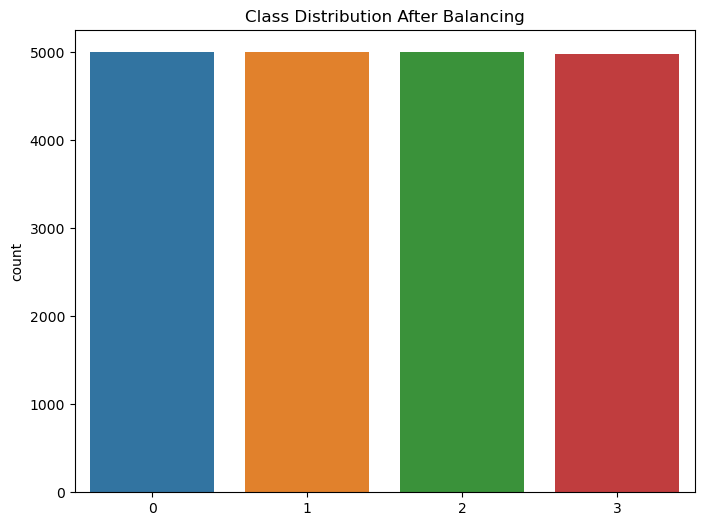

In [23]:
# Visualize balanced class distribution
plt.figure(figsize=(8,6))
sns.countplot(x=y_train_balanced)
plt.title("Class Distribution After Balancing")
plt.show()

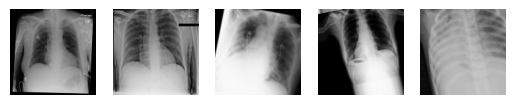

In [24]:
# Display the first 5 augmented images
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_train_balanced[i])  # Display the image
    plt.axis('off')
plt.show()

In [25]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical


In [26]:
# Convert labels to categorical (one-hot encoding)
num_classes = len(np.unique(y_train_balanced))
y_train_cat = to_categorical(y_train_balanced, num_classes)
y_test_cat = to_categorical(y_test, num_classes)


In [27]:
# Create the base model
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,  # Exclude final dense layer
    input_tensor=Input(shape=(128, 128, 3))  # Resize to 3 channels if needed
)


In [28]:
# Freeze all layers in the base initially
for layer in base_model.layers:
    layer.trainable = False


In [29]:
# Custom top layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(num_classes, activation='softmax')(x)

In [30]:
# Build model
model = Model(inputs=base_model.input, outputs=predictions)


In [31]:
# Compile
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 134, 134,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 64, 64,    │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 64, 64,    │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 64, 64,    │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 66, 66,    │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 32, 32,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 32, 32,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 32, 32,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 32, 32,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 32, 32,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 32, 32,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 32, 32,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 32, 32,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 32, 32,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 32, 32,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 32, 32,    │     12,288 │ conv2_block2_0_r

 Total params: 7,300,932 (27.85 MB)

 Trainable params: 263,428 (1.00 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [32]:
# Callbacks
early_stop = EarlyStopping(patience=5, restore_best_weights=True, verbose=1)
reduce_lr = ReduceLROnPlateau(patience=3, factor=0.2, verbose=1)
checkpoint = ModelCheckpoint("best_model.keras", save_best_only=True, verbose=1)


In [ ]:
# Train
history = model.fit(
    X_train_balanced, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 589ms/step - accuracy: 0.6389 - loss: 0.9805
Epoch 1: val_loss improved from inf to 0.65027, saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 515s 709ms/step - accuracy: 0.6390 - loss: 0.9801 - val_accuracy: 0.7531 - val_loss: 0.6503 - learning_rate: 0.0010
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7623 - loss: 0.5992
Epoch 2: val_loss improved from 0.65027 to 0.53522, saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 1525s 2s/step - accuracy: 0.7623 - loss: 0.5991 - val_accuracy: 0.8122 - val_loss: 0.5352 - learning_rate: 0.0010
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7796 - loss: 0.5575
Epoch 3: val_loss improved from 0.53522 to 0.51065, saving model to best_model.keras
625/625 ━━━━━━━━━━━━━━━━━━━━ 1527s 2s/step - accuracy: 0.7796 - loss: 0.5575 - val_accuracy: 0.8056 - val_loss: 0.5107 - learning_rate: 0.0010
Epoch 4/10
410/625 ━━━━━━━━━━━━━━━━━━━━ 2:11:44 37s/step - a